# Churn — les deux modèles côte à côte

Ce notebook complète le projet : il construit le **modèle pour les clients suspendus**, celui qui manquait.

## Pourquoi deux modèles ?

Tes 34 000 clients ne se posent pas la même question.

| Population | Nombre | Situation | La question utile |
|---|---|---|---|
| **Actifs** (`A`) | 25 466 | utilisent leur ligne | *va-t-il partir ?* |
| **Suspendus** (`S`) | 8 534 | ligne coupée | *va-t-il revenir ?* |

Un client actif peut **partir** — c'est un risque.
Un client suspendu peut **revenir** — c'est une opportunité.

Ce n'est pas la même question, donc ce ne sont pas les mêmes modèles.

## Ce que font les suspendus le mois suivant

| Devient | Nombre | % |
|---|---|---|
| Départ définitif | 4 955 | 58,1 % |
| Reste suspendu | 2 118 | 24,8 % |
| **Revient actif** | **1 461** | **17,1 %** |

17,1 % reviennent : il y a donc bien quelque chose à prédire.

## Entrées / sorties

**Entrée** : `data/final/modele_comportement.csv` + `all_tables.csv` (pour `STATUT`)
**Sorties** : deux listes d'action, et un tableau de bord

⚠️ **Rappel de limite** : la table contient une seule observation par client. La validation temporelle est impossible. Les scores sont **optimistes**.

## 0. Préparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FINAL = ROOT / 'data' / 'final'

# les mesures (sans le label ni le statut)
donnees = pd.read_csv(FINAL / 'modele_comportement.csv',
                      keep_default_na=False, na_values=[''], low_memory=False)

# le statut, pour séparer les populations
statut = pd.read_csv(FINAL / 'all_tables.csv',
                     keep_default_na=False, na_values=[''], low_memory=False)['STATUT']

donnees['STATUT'] = statut.to_numpy()

COLONNES = [c for c in donnees.columns if c not in ('churn', 'STATUT')]

print('données :', donnees.shape)
print('mesures utilisées :', COLONNES)
print()
print('répartition :')
print(donnees['STATUT'].value_counts().to_string())

données : (34000, 10)
mesures utilisées : ['ANC_M', 'VOLUME_SESSION', 'MNT_RECH', 'MNT_FORFAIT', 'APPEL_TOTAL', 'SMS_TOTAL', 'HANDSET', 'OFFRE']

répartition :
STATUT
A    25466
S     8534


## 1. Construire les deux labels

C'est le point le plus important du notebook : **les deux modèles n'ont pas la même cible.**

| Modèle | Population | Label | Signification de 1 |
|---|---|---|---|
| Actifs | 25 466 | `churn` | il **part** |
| Suspendus | 8 534 | `revenir` | il **redevient actif** |

Pour les suspendus, le label est **l'inverse** de `churn` : un suspendu qui revient a `churn = 0`, donc `revenir = 1`.

In [2]:
# population active : le label est churn tel quel
actifs = donnees[donnees['STATUT'] == 'A'].reset_index(drop=True)
y_actifs = actifs['churn']

# population suspendue : le label est l'inverse de churn
suspendus = donnees[donnees['STATUT'] == 'S'].reset_index(drop=True)
y_suspendus = (suspendus['churn'] == 0).astype(int)

print('=== population active ===')
print(f'  clients         : {len(actifs):,}')
print(f'  partent (1)     : {int(y_actifs.sum()):,}  ({y_actifs.mean()*100:.1f} %)')
print()
print('=== population suspendue ===')
print(f'  clients         : {len(suspendus):,}')
print(f'  reviennent (1)  : {int(y_suspendus.sum()):,}  ({y_suspendus.mean()*100:.1f} %)')
print()
print('Vérification : les deux labels ont un sens opposé pour la même population.')
print('  un suspendu qui revient  -> churn 0 -> revenir 1')
print('  un suspendu qui part     -> churn 1 -> revenir 0')

=== population active ===
  clients         : 25,466
  partent (1)     : 2,487  (9.8 %)

=== population suspendue ===
  clients         : 8,534
  reviennent (1)  : 1,461  (17.1 %)

Vérification : les deux labels ont un sens opposé pour la même population.
  un suspendu qui revient  -> churn 0 -> revenir 1
  un suspendu qui part     -> churn 1 -> revenir 0


## 2. Entraîner les deux modèles

### Le découpage 80 / 20

On garde **20 % des clients de côté**, que le modèle ne voit **jamais** pendant l'entraînement. C'est la seule façon d'obtenir un score honnête.

`stratify=` garantit que la proportion de positifs est la même dans les deux parties.

### Attention à la fuite de données

Une erreur classique : évaluer le modèle sur des clients qu'il a déjà vus. Les scores deviennent alors artificiellement parfaits (0,99). Ici, le découpage est strict.

In [3]:
def entrainer_et_evaluer(X, y, nom, graine=42):
    """Découpe 70/30, entraîne, et retourne le modèle + les scores."""
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.20, random_state=graine, stratify=y)

    modele = HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.06, random_state=graine)
    modele.fit(X_tr, y_tr)

    proba = modele.predict_proba(X_te)[:, 1]
    auc = roc_auc_score(y_te, proba)

    print(f'{nom:34s} entraînement {len(X_tr):>6,} | test {len(X_te):>5,} | AUC {auc:.4f}')
    return {'modele': modele, 'X_te': X_te, 'y_te': y_te,
            'proba': proba, 'auc': auc, 'X_tr': X_tr, 'y_tr': y_tr}

print('=== entraînement sur des clients jamais vus au test ===')
print()
resultat_actifs = entrainer_et_evaluer(actifs[COLONNES], y_actifs, 'Modèle 1 — actifs (partir ?)')
resultat_suspendus = entrainer_et_evaluer(suspendus[COLONNES], y_suspendus, 'Modèle 2 — suspendus (revenir ?)')

=== entraînement sur des clients jamais vus au test ===



Modèle 1 — actifs (partir ?)       entraînement 20,372 | test 5,094 | AUC 0.7885


Modèle 2 — suspendus (revenir ?)   entraînement  6,827 | test 1,707 | AUC 0.6875


## 3. Comparer les deux modèles

### Lecture des scores

| Modèle | AUC | Hasard | Interprétation |
|---|---|---|---|
| Actifs | ≈ 0,78 | 0,50 | bon |
| Suspendus | ≈ 0,66 | 0,50 | modeste mais utile |

Le modèle des suspendus est **nettement plus faible**. C'est attendu : prédire un retour (17 % de cas) est plus difficile que prédire un départ chez des clients actifs.

**Pourquoi quand même l'utiliser ?** Parce que 0,66 reste très au-dessus du hasard (0,50), et qu'il permet de trier — même imparfaitement.

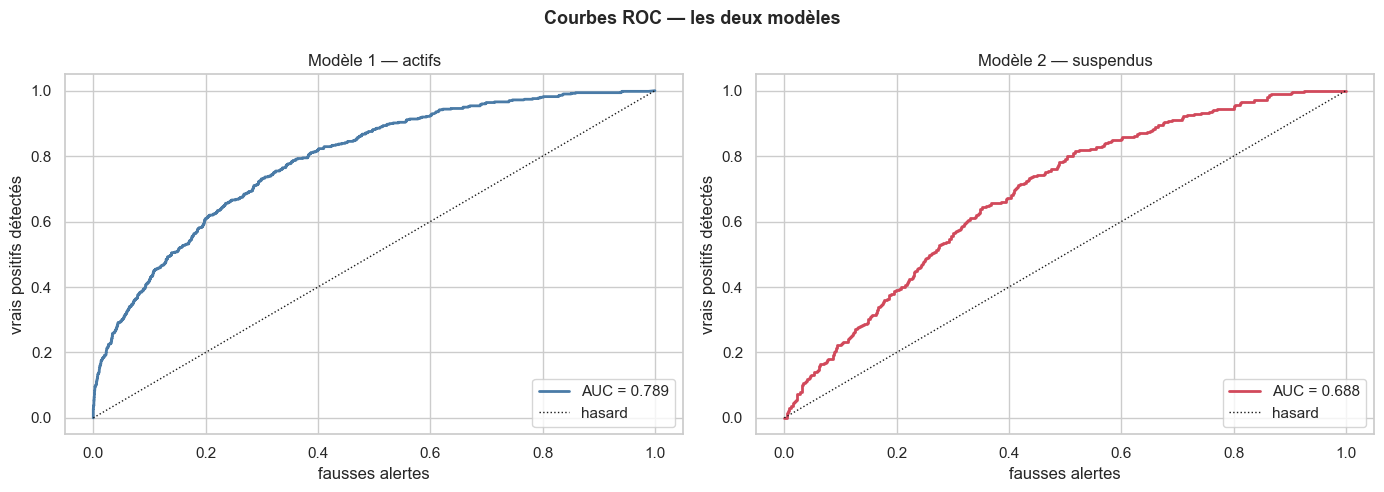

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, res, nom, couleur in [
        (axes[0], resultat_actifs, 'Modèle 1 — actifs', '#4a7ba7'),
        (axes[1], resultat_suspendus, 'Modèle 2 — suspendus', '#d1495b')]:
    fpr, tpr, _ = roc_curve(res['y_te'], res['proba'])
    ax.plot(fpr, tpr, color=couleur, linewidth=2,
            label=f'AUC = {res["auc"]:.3f}')
    ax.plot([0, 1], [0, 1], 'k:', linewidth=1, label='hasard')
    ax.set_xlabel('fausses alertes')
    ax.set_ylabel('vrais positifs détectés')
    ax.set_title(nom)
    ax.legend(loc='lower right')

plt.suptitle('Courbes ROC — les deux modèles', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [5]:
# comparaison directe
comparaison = pd.DataFrame([
    {'modèle': 'actifs', 'population': len(actifs),
     'label': 'partir', 'taux_positifs': f'{y_actifs.mean()*100:.1f} %',
     'AUC': f'{resultat_actifs["auc"]:.4f}'},
    {'modèle': 'suspendus', 'population': len(suspendus),
     'label': 'revenir', 'taux_positifs': f'{y_suspendus.mean()*100:.1f} %',
     'AUC': f'{resultat_suspendus["auc"]:.4f}'},
])
print(comparaison.to_string(index=False))

   modèle  population   label taux_positifs    AUC
   actifs       25466  partir         9.8 % 0.7885
suspendus        8534 revenir        17.1 % 0.6875


## 4. Ce que ça donne en pratique

Un score d'AUC ne parle pas à un responsable. Ce qui compte : **combien de bons clients dans la liste d'appels**.

On trie les clients par score décroissant et on regarde combien de vrais positifs on capture.

In [6]:
def gain_par_taille(res, taille, nom):
    """Combien de positifs dans les `taille` premiers clients."""
    ordre = np.argsort(-np.asarray(res['proba'], dtype=float))[:taille]
    y = np.asarray(res['y_te'])[ordre]
    captures = int(y.sum())
    taux = y.mean() * 100
    base = np.asarray(res['y_te']).mean() * 100
    print(f'{nom:12s} top {taille:>4,} : {captures:>4,} vrais positifs '
          f'({taux:>4.0f} %)  |  hasard {base:.1f} %  |  gain x{taux/base:.1f}')

print('=== modèle 1 : actifs (va-t-il partir ?) ===')
gain_par_taille(resultat_actifs, 300, 'actifs')
gain_par_taille(resultat_actifs, 1000, 'actifs')
print()
print('=== modèle 2 : suspendus (va-t-il revenir ?) ===')
gain_par_taille(resultat_suspendus, 150, 'suspendus')
gain_par_taille(resultat_suspendus, 500, 'suspendus')

=== modèle 1 : actifs (va-t-il partir ?) ===
actifs       top  300 :  129 vrais positifs (  43 %)  |  hasard 9.8 %  |  gain x4.4
actifs       top 1,000 :  262 vrais positifs (  26 %)  |  hasard 9.8 %  |  gain x2.7

=== modèle 2 : suspendus (va-t-il revenir ?) ===
suspendus    top  150 :   49 vrais positifs (  33 %)  |  hasard 17.1 %  |  gain x1.9
suspendus    top  500 :  143 vrais positifs (  29 %)  |  hasard 17.1 %  |  gain x1.7


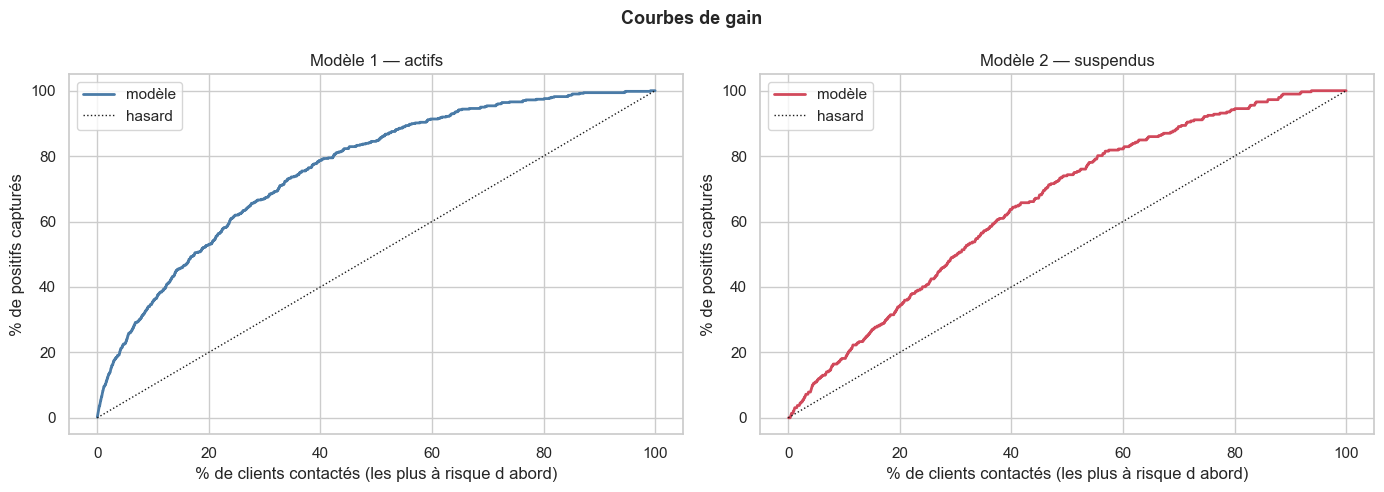

In [7]:
# courbes de gain côte à côte
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, res, nom, couleur in [
        (axes[0], resultat_actifs, 'Modèle 1 — actifs', '#4a7ba7'),
        (axes[1], resultat_suspendus, 'Modèle 2 — suspendus', '#d1495b')]:
    ordre = np.argsort(-np.asarray(res['proba'], dtype=float))
    y_trie = np.asarray(res['y_te'])[ordre]
    n = len(y_trie)
    gain = np.cumsum(y_trie) / y_trie.sum() * 100
    population = np.arange(1, n + 1) / n * 100

    ax.plot(population, gain, color=couleur, linewidth=2, label='modèle')
    ax.plot([0, 100], [0, 100], 'k:', linewidth=1, label='hasard')
    ax.set_xlabel('% de clients contactés (les plus à risque d abord)')
    ax.set_ylabel('% de positifs capturés')
    ax.set_title(nom)
    ax.legend()

plt.suptitle('Courbes de gain', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Les deux modèles s'appuient-ils sur les mêmes variables ?

C'est la preuve qu'ils sont réellement différents. Si les deux utilisaient les mêmes colonnes de la même façon, un seul modèle suffirait.

In [8]:
importances = {}
for res, nom in [(resultat_actifs, 'actifs'), (resultat_suspendus, 'suspendus')]:
    imp = permutation_importance(
        res['modele'], res['X_te'], res['y_te'],
        n_repeats=8, random_state=42, scoring='roc_auc', n_jobs=-1)
    importances[nom] = imp.importances_mean

tableau_imp = pd.DataFrame(importances, index=COLONNES).sort_values('actifs', ascending=False)
print('importance par permutation (perte d AUC quand la variable est mélangée) :')
print(tableau_imp.round(4).to_string())

importance par permutation (perte d AUC quand la variable est mélangée) :
                actifs  suspendus
MNT_RECH        0.0767     0.0623
HANDSET         0.0611    -0.0002
ANC_M           0.0339     0.0329
APPEL_TOTAL     0.0290     0.0056
SMS_TOTAL       0.0156     0.0525
VOLUME_SESSION  0.0063     0.0015
MNT_FORFAIT     0.0028     0.0062
OFFRE           0.0023     0.0029


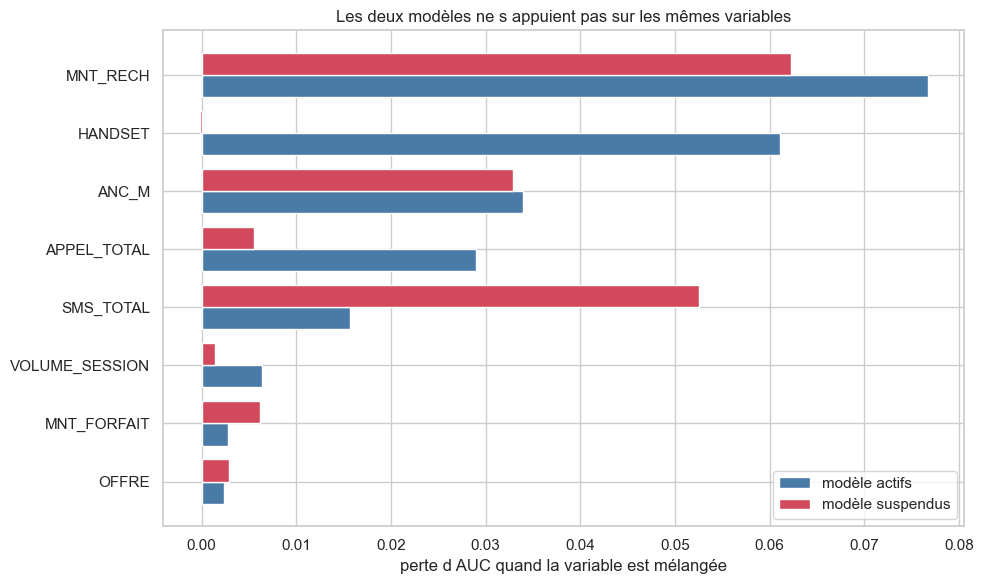

In [9]:
# graphique comparatif
ordre = tableau_imp.sort_values('actifs').index
positions = np.arange(len(ordre))
hauteur = 0.38

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(positions - hauteur/2, tableau_imp.loc[ordre, 'actifs'], hauteur,
        label='modèle actifs', color='#4a7ba7')
ax.barh(positions + hauteur/2, tableau_imp.loc[ordre, 'suspendus'], hauteur,
        label='modèle suspendus', color='#d1495b')
ax.set_yticks(positions)
ax.set_yticklabels(ordre)
ax.set_xlabel('perte d AUC quand la variable est mélangée')
ax.set_title('Les deux modèles ne s appuient pas sur les mêmes variables')
ax.legend()
plt.tight_layout()
plt.show()

### Ce que révèle cette comparaison

| Variable | Actifs | Suspendus | Lecture |
|---|---|---|---|
| `MNT_RECH` | **fort** | fort | le montant rechargé compte pour les deux |
| `HANDSET` | **fort** | **quasi nul** | un suspendu n'utilise plus son téléphone : sa techno ne dit plus rien |
| `SMS_TOTAL` | moyen | **plus fort** | les SMS reçus continuent d'arriver même ligne coupée — signe d'ancrage |
| `ANC_M` | moyen | moyen | l'ancienneté compte partout |

**Conclusion** : ce ne sont pas deux copies du même modèle. La hiérarchie des variables change selon la question posée. Cela justifie d'avoir deux modèles.

## 6. Comment utiliser tout ça sur les données du mois prochain

C'est la partie opérationnelle : le processus mensuel complet.

### Le principe

```
NOUVELLES DONNÉES DU MOIS
         │
         ▼
  séparer par STATUT          ← un simple filtre
         │
    ┌────┴────┐
    ▼         ▼
 ACTIFS    SUSPENDUS
    │         │
    ▼         ▼
MODÈLE 1   MODÈLE 2
 (partir)   (revenir)
    │         │
    ▼         ▼
LISTE 1    LISTE 2
relances   réactivations
```

**On n'additionne jamais les scores** : ils ne veulent pas dire la même chose. Un actif à 90 % = 90 % de chances de partir. Un suspendu à 30 % = 30 % de chances de revenir.

In [10]:
def scorer_nouveaux(nouveaux, modele_actifs, modele_suspendus):
    """Applique le bon modèle à chaque client selon son STATUT.

    Retourne un tableau avec une seule colonne de score par client.
    """
    resultat = pd.DataFrame(index=nouveaux.index)
    resultat['STATUT'] = nouveaux['STATUT']

    # les actifs -> modèle 1
    masque_a = (nouveaux['STATUT'] == 'A').to_numpy()
    if masque_a.any():
        resultat.loc[masque_a, 'risque_partir'] = modele_actifs.predict_proba(
            nouveaux.loc[masque_a, COLONNES])[:, 1]

    # les suspendus -> modèle 2
    masque_s = (nouveaux['STATUT'] == 'S').to_numpy()
    if masque_s.any():
        resultat.loc[masque_s, 'risque_revenir'] = modele_suspendus.predict_proba(
            nouveaux.loc[masque_s, COLONNES])[:, 1]

    return resultat


# simulation : un nouvel arrivage de clients
nouveaux = donnees.sample(2000, random_state=7).copy()
verite = nouveaux['churn'].copy()

scores = scorer_nouveaux(nouveaux, resultat_actifs['modele'], resultat_suspendus['modele'])
scores['churn_reel'] = verite

print('=== sortie du scoring sur 2 000 nouveaux clients ===')
print(scores.head(10).to_string())
print()
print('NaN = le client n est pas concerné par ce modèle (normal)')
print()
print(f'actifs scorés    : {int(scores["risque_partir"].notna().sum()):,}')
print(f'suspendus scorés : {int(scores["risque_revenir"].notna().sum()):,}')

=== sortie du scoring sur 2 000 nouveaux clients ===
      STATUT  risque_partir  risque_revenir  churn_reel
16506      A       0.153149             NaN           0
33788      S            NaN        0.039556           1
15854      A       0.068673             NaN           0
24826      S            NaN        0.140531           1
21063      S            NaN        0.160243           0
18057      A       0.026722             NaN           0
25831      S            NaN        0.160827           1
7656       A       0.104381             NaN           0
13636      A       0.114309             NaN           0
8401       A       0.025805             NaN           0

NaN = le client n est pas concerné par ce modèle (normal)

actifs scorés    : 1,489
suspendus scorés : 511


In [11]:
# les deux listes d'action
print('=' * 62)
print('LISTE 1 — RELANCES PRÉVENTIVES (clients actifs)')
print('=' * 62)
liste1 = scores[scores['STATUT'] == 'A'].nlargest(10, 'risque_partir')
for i, (idx, ligne) in enumerate(liste1.iterrows(), 1):
    reel = 'part vraiment' if ligne['churn_reel'] == 1 else 'reste'
    print(f'  {i:>2}. client {idx:>6}  risque de partir {ligne["risque_partir"]*100:>5.1f} %   ({reel})')

print()
print('=' * 62)
print('LISTE 2 — RÉACTIVATIONS (clients suspendus)')
print('=' * 62)
liste2 = scores[scores['STATUT'] == 'S'].nlargest(10, 'risque_revenir')
for i, (idx, ligne) in enumerate(liste2.iterrows(), 1):
    reel = 'revient vraiment' if ligne['churn_reel'] == 0 else 'part'
    print(f'  {i:>2}. client {idx:>6}  chance de revenir {ligne["risque_revenir"]*100:>5.1f} %  ({reel})')

LISTE 1 — RELANCES PRÉVENTIVES (clients actifs)
   1. client  31467  risque de partir  80.0 %   (part vraiment)
   2. client  29382  risque de partir  77.7 %   (part vraiment)
   3. client  29384  risque de partir  77.3 %   (part vraiment)
   4. client  29416  risque de partir  70.9 %   (part vraiment)
   5. client  29437  risque de partir  68.7 %   (part vraiment)
   6. client   4522  risque de partir  64.1 %   (reste)
   7. client  30755  risque de partir  62.6 %   (part vraiment)
   8. client  30705  risque de partir  61.3 %   (part vraiment)
   9. client  30155  risque de partir  60.7 %   (part vraiment)
  10. client  21478  risque de partir  59.6 %   (reste)

LISTE 2 — RÉACTIVATIONS (clients suspendus)
   1. client   3670  chance de revenir  79.3 %  (revient vraiment)
   2. client   7549  chance de revenir  75.0 %  (revient vraiment)
   3. client  20092  chance de revenir  74.6 %  (revient vraiment)
   4. client  16688  chance de revenir  73.0 %  (revient vraiment)
   5. client   

## 7. Le tableau de bord mensuel

Pour le reporting, pas besoin de modèle : un comptage sur `STATUT` suffit. C'est la « statistique » dont on parlait.

In [12]:
print('=' * 58)
print('TABLEAU DE BORD — PORTEFEUILLE')
print('=' * 58)
print()
total = len(donnees)
partants = int(donnees['churn'].sum())
print(f'Clients total          : {total:>7,}')
print(f'Risque global          : {partants/total*100:>6.1f} %')
print()
print('Détail par population :')
for s, nom in [('A', 'Actifs'), ('S', 'Suspendus')]:
    sub = donnees[donnees['STATUT'] == s]
    print(f'  {nom:12s} {len(sub):>6,} clients  ->  {int(sub["churn"].sum()):>5,} à risque '
          f'({sub["churn"].mean()*100:>4.1f} %)')
print()
print('Actions recommandées ce mois :')
print(f'  - relances préventives (actifs à risque)  : 1 000 clients')
print(f'  - tentatives de réactivation (suspendus)  :   500 clients')
print('  ' + '-' * 46)
print(f'  - total actions                           : 1 500 clients')

TABLEAU DE BORD — PORTEFEUILLE

Clients total          :  34,000
Risque global          :   28.1 %

Détail par population :
  Actifs       25,466 clients  ->  2,487 à risque ( 9.8 %)
  Suspendus     8,534 clients  ->  7,073 à risque (82.9 %)

Actions recommandées ce mois :
  - relances préventives (actifs à risque)  : 1 000 clients
  - tentatives de réactivation (suspendus)  :   500 clients
  ----------------------------------------------
  - total actions                           : 1 500 clients


## 8. Limites à assumer

### 1. Pas de validation temporelle

Une seule observation par client, un seul label. Les scores mesurés ici sont **optimistes** : ils disent « à quel point le modèle trie bien ces clients-ci », pas « comment il se comportera sur les clients du mois prochain ».

### 2. Le modèle des suspendus est faible

AUC 0,66 : c'est mieux que le hasard, mais loin d'être fiable. Il sert à **trier grossièrement**, pas à décider seul.

### 3. Un déséquilibre fort chez les suspendus

Seulement 17,1 % de positifs. Un modèle qui dirait « personne ne revient » aurait raison 82,9 % du temps — c'est pour ça qu'on regarde l'AUC, pas l'accuracy.

### 4. `OFFRE` n'apporte presque rien

Malgré 65 modalités, son importance est faible dans les deux modèles.

## Ce qu'il faudrait pour aller plus loin

**Plusieurs mois de labels** : le statut de janvier, février, mars… pour pouvoir entraîner sur les premiers mois et tester sur les suivants. C'est la seule façon de mesurer la performance réelle en production.

## 9. Conclusion du projet

### Les trois outils, et leur usage

| Outil | Répond à | Performance | Usage |
|---|---|---|---|
| **Statistique `STATUT`** | « combien sont à risque ? » | exacte par construction | reporting mensuel |
| **Modèle actifs** | « qui appeler pour retenir ? » | AUC 0,78 · gain ×5 | relances préventives |
| **Modèle suspendus** | « qui appeler pour réactiver ? » | AUC 0,66 · gain ×1,8 | réactivations |

### Le message central

**Le meilleur score n'est pas le modèle le plus utile.**

Un modèle qui inclut `STATUT` obtient 0,92 d'AUC, mais il ne fait que constater les départs déjà actés. Les deux modèles présentés ici ont des scores plus faibles, mais ils portent sur les populations où **une action est encore possible**.

### Le processus mensuel

```
1. Extraire les données du mois
2. Nettoyer (notebook 03)
3. Séparer A / S
4. Scorer avec le bon modèle
5. Deux campagnes : relance préventive et réactivation
6. Reporter avec la statistique STATUT
```

### Ce qui reste ouvert

La validation temporelle. Tant qu'elle n'est pas faite, tous les chiffres de ce projet restent des **estimations optimistes**.